# 自然语言处理

## 1 古典方法

本章先介绍古典方法，即深度学习出现以前的方法。

### 1.1 同义词词典

在同义词词典（thesaurus）中，具有相同含义的单词（同义词）或含义类似的单词（近义词）被归类到同一个组中。另外，在自然语言处理中用到的同义词词典有时会定义单词之间的粒度更细的关系，比如“上位-下位”关系、“整体-部分”关系。

在自然语言处理领域，最著名的同义词词典是普林斯顿大学于1985年开始开发的WordNet。使用WordNet，可以获得单词的近义词，或者利用单词网络计算单词之间的相似度。

同义词词典也存在一些较大的缺陷：

1. 难以顺应时代的变化：新词、新含义不断出现。
2. 人力成本高。
3. 无法表示近义词之间的细微差别。

为了避免这些问题，接下来我们将介绍基于计数的方法和利用神经网络的基于推理的方法。这两种方法可以从海量的文本数据中自动提取单词含义，将我们从人工关联单词的辛苦劳动中解放出来。

### 1.2 基于计数的方法

首先需要对语料库进行预处理，这里的预处理是将文本分割为单词，并将分割后的单词列表转化为单词ID列表。corpus是单词ID列表，word_to_id是单词到单词ID的字典，id_to_word是单词ID到单词的字典。

In [ ]:
import numpy as np

def preprocess(text):

    text = text.lower()
    text = text.replace('.', ' .')
    words = text.split(' ')
    word_to_id = {}
    id_to_word = {}
    for word in words:
        if word not in word_to_id:
            new_id = len(word_to_id)
            word_to_id[word] = new_id
            id_to_word[new_id] = word
    corpus = np.array([word_to_id[w] for w in words])

    return corpus, word_to_id, id_to_word

text = 'You say goodbye and I say hello.'
corpus, word_to_id, id_to_word = preprocess(text)
print(corpus, word_to_id, id_to_word)

[0 1 2 3 4 1 5 6] {'you': 0, 'say': 1, 'goodbye': 2, 'and': 3, 'i': 4, 'hello': 5, '.': 6} {0: 'you', 1: 'say', 2: 'goodbye', 3: 'and', 4: 'i', 5: 'hello', 6: '.'}


分布式假设：某个单词的含义由它周围的单词形成。单词的分布式表示将单词表示为固定长度的向量，最直截了当的实现方法是对周围单词的数量进行计数。这里，我们将上下文的大小（周围单词的数量）称为窗口大小（window size）。简单起见，这里仅处理不考虑句子分隔符、左右单词数量相同的上下文。窗口大小为1，上下文包含左右各1个单词；窗口大小为2，上下文包含左右各2个单词，以此类推。

以上面的句子为例，我们将窗口大小设为1，从id为0的单词you开始计数。you的上下文仅有say这个单词，say的id为1，因此可以用向量[0, 1, 0, 0, 0, 0, 0]表示单词you。接下来看id为1的say，第一个say的上下文是you和goodbye，第二个say的上下文是i和hello，因此，可以用向量[1, 0, 1, 0, 1, 1, 0]来表示单词say。以此类推，可以得到七个向量，将其组合在一起，便可得到一个矩阵，称为共现矩阵（co-occurence matrix）。

In [3]:
def create_co_matrix(corpus, window_size = 1):

    vocab_size = np.unique(corpus).size
    co_matrix = np.zeros((vocab_size, vocab_size)) 
    for index, token_id in enumerate(corpus):
        for i in range(1, window_size + 1):
            if index >= i:
                co_matrix[token_id][corpus[index - i]] += 1
            if index <= len(corpus) - i - 1:
                co_matrix[token_id][corpus[index + i]] += 1

    return co_matrix

matrix = create_co_matrix(corpus)
print(matrix)

[[0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 1. 0. 1. 1. 0.]
 [0. 1. 0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 1. 0. 0.]
 [0. 1. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1. 0.]]


向量间的相似度可以用向量内积、欧氏距离等方法测量。在词向量的相似度方面，余弦相似度较为常用。设有$\bm{x}=(x_1,x_2,\cdots,x_n)$和$\bm{y}=(y_1,y_2,\cdots,y_n)$两个向量，它们之间的余弦相似度定义为
$$\cos(\theta)=\frac{\bm{x}\cdot\bm{y}}{\lVert A\rVert\lVert B\rVert}$$
余弦相似度直观地表示了“两个向量在多大程度上指向同一方向”。两个向量完全指向相同的方向时，余弦相似度为1；完全指向相反的方向时，余弦相似度为−1。

实现的时候，会给向量模长加上一个微小值$\varepsilon$以防止除0错误。

In [4]:
def cos_similarity(x, y, epsilon = 1e-8):

    f = lambda z: np.linalg.norm(z) + epsilon
    
    return np.dot(x, y) / (f(x) * f(y))

v1 = matrix[word_to_id['you']]
v2 = matrix[word_to_id['i']]
print(cos_similarity(v1, v2))

0.7071067691154799


使用cos_similarity函数时，我们可以实现另一个便利的函数：当某个单词被作为查询词时，将与这个查询词相似的单词按降序显示出来。

In [27]:
def most_similar(query, word_to_id, id_to_word, word_matrix, top=5):

    vocab_size = len(word_matrix)
    query_id = word_to_id[query]
    similarities = np.zeros(vocab_size)
    for i in range(vocab_size):
        if i != query_id:
            similarities[i] = cos_similarity(word_matrix[query_id], word_matrix[i])
    top_indices = np.argsort(similarities, descending=True)
    for index in top_indices[:top]:
        print(id_to_word[index], similarities[index])

most_similar("you", word_to_id, id_to_word, matrix)

goodbye 0.7071067691154799
i 0.7071067691154799
hello 0.7071067691154799
you 0.0
say 0.0


### 1.3 基于计数的方法的改进

上一节的共现矩阵的元素表示两个单词同时出现的次数。但是，这种“原始”的次数并不具备好的性质。如果我们看一下高频词，就能明白其原因了。比如，考虑某个语料库中the和car共现的情况。在这种情况下，它们的共现次数将会很大。我们已知car和drive也有很强的相关性。但是，如果只看单词的出现次数，那么与drive相比，the和car的相关性更强。这意味着，仅仅因
为the是个常用词，它就被认为与car有很强的相关性。

为了解决这一问题，可以使用点互信息（Pointwise Mutual Information，PMI）这一指标。对于随机变量x和y，它们的PMI定义为
$$
\mathrm{PMI}(x,y)=\log_2\frac{\Pr{(x,y)}}{\Pr{(x)}\Pr{(y)}}
$$
在具体实现中，为了从共现矩阵求PMI，将$\Pr{(x)}$定义为单词$x$与所有单词共现的概率、$\Pr{(x,y)}$定义为单词$x$和$y$共现的概率。设共现矩阵为$\bm{C}$，$x$和$y$的共现次数为$\bm{C}(x,y)$，单词$x$和$y$与所有单词的共现次数分别为$\bm{C}(x)$、$\bm{C}(y)$，所有单词与所有单词的共现次数（共现矩阵的元素之和）为$N$，则有
$$
\hat{\mathrm{PMI}}(x,y)=\log_2\frac{\frac{\bm{C}(x,y)}{N}}{\frac{\bm{C}(x)}{N}\frac{\bm{C}(y)}{N}}=\log_2 \frac{N\cdot \bm{C}(x,y)}{\bm{C}(x)\bm{C}(y)}
$$
下面我们来具体地算一下。假设N为10000，C(the)=100，C(car)=20，C(drive)=10，C(the,car)=10，C(car,drive)=5。如果从共现次数的角度来看，则与drive相比，the和car的相关性更强。而如果从PMI的角度来看，PMI("the","car")≈2.32，PMI("car","drive")≈7.97，与the相比，drive和car具有更强的相关性。这是因为为the本身出现得多，所以PMI的得分被拉低了。

虽然我们已经获得了PMI这样一个好的指标，但是PMI也有一个问题。那就是当两个单词的共现次数为0时，$log_2 0=−\infty$。为了解决这个问题，实践上我们会使用下述正的点互信息（Positive PMI，PPMI）：
$$
\mathrm{PPMI}(x,y)=\max(0,\mathrm{PMI}(x,y))
$$

In [24]:
def ppmi(c, epsilon = 1e-8):
    
    c_1 = np.zeros_like(c)
    n = np.sum(c)
    c_i = np.sum(c, axis=0)
    for i in range(np.size(c, axis=0)):
        for j in range(np.size(c, axis=1)):
            c_1[i][j] = max(0, np.log2(n * c[i][j] / (c_i[i] * c_i[j]) + epsilon))
    
    return c_1

matrix_ppmi = ppmi(matrix)
print(np.around(matrix_ppmi, 3))

[[0.    1.807 0.    0.    0.    0.    0.   ]
 [1.807 0.    0.807 0.    0.807 0.807 0.   ]
 [0.    0.807 0.    1.807 0.    0.    0.   ]
 [0.    0.    1.807 0.    1.807 0.    0.   ]
 [0.    0.807 0.    1.807 0.    0.    0.   ]
 [0.    0.807 0.    0.    0.    0.    2.807]
 [0.    0.    0.    0.    0.    2.807 0.   ]]


但是，这个PPMI矩阵还是存在一个很大的问题，那就是随着语料库的词汇量增加，各个单词向量的维数也会增加。另外，这个矩阵的很多元素都是0，这样的矩阵称为稀疏矩阵（sparse matrix）。这表明向量中的绝大多数元素并不重要。另外，这样的矩阵也容易受到噪声影响，稳健性差。对于这些问题，一个常见的方法是降维。降维（dimensionality reduction）就是从稀疏矩阵中找出重要的轴，用更少的维度对其进行重新表示。这样，稀疏矩阵就会被转化为大多数元素均不为0的密集矩阵。

降维的方法有很多，这里我们使用奇异值分解（Singular Value Decomposition，SVD）。SVD将任意m×n矩阵分解为3个矩阵的乘积，即
$$
\bm{X}=\bm{USV^\top}
$$
其中$\bm{U}_{m\times m}$和$\bm{V}_{n\times n}$是列向量彼此正交的正交矩阵，$\bm{U}$的列向量为$\bm{A}$的左奇异向量，对应$\bm{AA^\top}$的特征向量；$\bm{V}$的列向量为$\bm{A}$的右奇异向量，对应$\bm{A^\top A}$的特征向量，$\bm{S}_{m\times n}$是对角线上的元素为从大到小排列的奇异值、其他元素均为零的对角矩阵。

矩阵S中的奇异值越小，对应U中列向量的重要性越低。因此，可以通过去除矩阵U中列数较大的列向量来近似原始矩阵。若$\bm{X}$是共现矩阵，则可通过取$\bm{U}$的前$k$列来实现降维。

[[ 3.40948752e-01  5.55111512e-16]
 [-1.11022302e-16 -5.97636386e-01]
 [ 4.36312209e-01  8.32667268e-17]
 [-6.66133815e-16 -4.97828132e-01]
 [ 4.36312209e-01  1.01521897e-16]
 [ 7.09237099e-01  1.01521897e-16]
 [ 1.05471187e-15 -6.28488585e-01]]


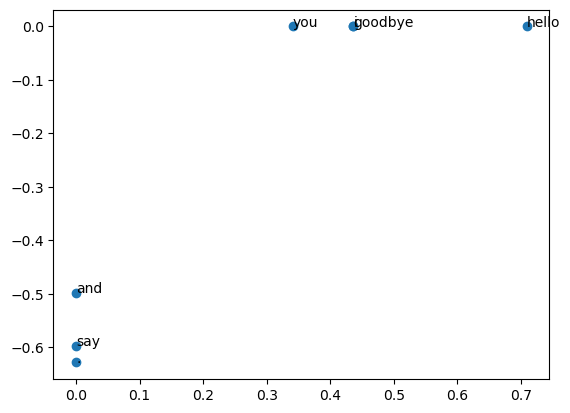

In [26]:
import matplotlib.pyplot as plt

u, s, v = np.linalg.svd(matrix_ppmi)
matrix_dr = u[:, :2]
print(matrix_dr)

for word, word_id in word_to_id.items():
    plt.annotate(word, (u[word_id, 0], u[word_id, 1]))
plt.scatter(u[:,0], u[:,1])
plt.show()

#### 1.3.4 PTB数据集

Penn Treebank（PTB）数据集是自然语言处理领域中广泛使用的语料库之一。它主要包含1989年《华尔街日报》的文章，总计约1百万个单词。

这里使用的数据进行了一些预处理，包括将稀有单词替换成特殊字符`<unk>`，将具体的数字替换成`N`等。此外，我们将所有句子连接起来，在每个句子的结尾处插入一个特殊字符`<eos>`，并将其视为一个大的时序数据。

In [29]:
def process(path):

    with open(path, 'r', encoding='utf-8') as f:
        data = f.read()
    text = data.replace('\n', '<eos>')
    words = text.split(' ')
    word_to_id = {}
    id_to_word = {}
    for word in words:
        if word not in word_to_id:
            new_id = len(word_to_id)
            word_to_id[word] = new_id
            id_to_word[new_id] = word
    corpus = np.array([word_to_id[w] for w in words])

    return corpus, word_to_id, id_to_word

path = r'..\assets\files\ptb.train.txt'
corpus, word_to_id, id_to_word = process(path)
window_size = 2
wordvec_size = 100
matrix_1 = create_co_matrix(corpus, window_size)
matrix_2 = ppmi(matrix_1)
matrix_3, _, _ = np.linalg.svd(matrix_2)
matrix_4 = matrix_3[:, :wordvec_size]
querys = ['you', 'year', 'car', 'toyota']
for query in querys:
    print(f'[query] {query} ')
    most_similar(query, word_to_id, id_to_word, matrix_4, top=5)

[query] you 
i 0.7003179246461481
we 0.6367183536569464
anybody 0.5657641139279953
do 0.5635669150196524
'll 0.5127798600451067
[query] year 
month 0.6961643558153409
quarter 0.6884943772320891
earlier 0.66633206888804
last 0.6281363169758839
next 0.6175754971393589
[query] car 
luxury 0.6728831298978494
auto 0.645210962549727
vehicle 0.6097722047748815
cars 0.6032832563850359
corsica 0.5698370249023308
[query] toyota 
motor 0.7585658143594997
nissan 0.7148031605433938
motors 0.6926157231236905
lexus 0.6583303330706008
honda 0.6350274437528599


观察结果可知，对于查询词you，可以看到i、we等人称代词排在前面，这些都是在语法上具有相同用法的词。再者，查询词year有month、quarter等近义词，查询词car有auto、vehicle等近义词。此外，将toyota作为查询词时，出现了nissan、honda和lexus等汽车制造商名或者品牌名。像这样，在含义或语法上相似的单词表示为相近的向量，这符合我们的直觉。

使用语料库，计算上下文中的单词数量，将它们转化PPMI矩阵，再基于SVD降维获得好的单词向量。这就是单词的分布式表示，每个单词表示为固定长度的密集向量。

## 2 word2vec

### 2.1 基于推理的方法

基于推理的方法的主要操作是推理，即给出某个位置周围的单词时，预测这个位置处会出现什么单词。基于推理的方法引入了神经网络，它接收上下文信息作为输入，并输出可能出现的各个单词的出现概率。作为模型学习的产物，我们得到了单词的分布式表示。由此可见，不管是哪种方法，如何对基于分布式假设的“单词共现”建模都是最重要的研究主题。

#### 2.1.1 单词的独热表示

要用神经网络处理单词，需要先将单词转化为固定长度的向量。对此，一种方式是将单词转换为独热向量（one-hot vector）。在独热表示中，只有一个元素是1，其他元素都是0。要将单词转化为独热表示，就需要准备元素个数与词汇个数相等的向量，并将单词ID对应的元素设为1，其他元素设为0。像这样，只要将单词转化为固定长度的向量，神经网络的输入层的神经元个数就可以固定下来。为了配合后文对word2vec的说明，本章使用的全连接层将省略偏置。

## 2.2 简单的word2vec

CBOW模型和skip-gram模型是word2vec中使用的两个神经网络模型。本节我们将主要讨论CBOW模型。

### CBOW模型

CBOW（Continuous Bag of Words）模型是根据上下文预测目标词的神经网络模型。CBOW模型的输入是['you', 'goodbye']这样的单词列表。我们将其转换为one-hot表示，以便模型可以进行处理。CBOW模型有两个输入层，经过中间层到达输出层。从输入层到中间层的变换由相同的全连接层（权重为$\bm{W}_{in}$）完成，从中间层到输出层神经元的变换由另一个全连接层（权重为$\bm{W}_{out}$）完成。这里，因为我们对上下文仅考虑两个单词，所以输入层有两个。如果对上下文考虑N个单词，则输入层会有N个。

中间层的神经元是各个输入层经全连接层变换后得到的值的平均。若经全连接层变换后，第1个输入层转化为$\bm{h}_1$，第2个输入层转化为$\bm{h}_2$，那么中间层的神经元是$\frac{1}{2}(\bm{h}_1+\bm{h}_2)$。中间层的神经元数量要比输入层少，因为中间层需要将预测单词所需的信息压缩保存，从而产生密集的向量表示。这时，中间层被写入了我们人类无法解读的数据，这相当于“编码”工作。而从中间层的信息获得期望结果的过程则称为“解码”。这一过程将被编码的信息复原为我们可以理解的形式。

输出层的神经元个数等于单个输入层的神经元个数。输出层的神经元是各个单词的得分，它的值越大，说明对应单词的出现概率就越高。得分是指在被解释为概率之前的值，对这些得分应用Softmax函数，就可以得到概率。

